# Scenario protocols compared on ANDES

Simulates a power system (`SYSTEM`: the IEEE 39-bus New England system or the German
transmission grid, see `docs/germany_model.md`) on the open-source ANDES engine under two
scenario protocols and compares machine-learning models on the resulting events:

* **baseline** - the setup of the bundled PowerFactory datasets (`ScenarioSampler`: one load
  step at t = 0, fault at a random time, fixed clearing, label from the out-of-step flag).
* **stress_test** - loading 80-120 % with re-dispatch, fault at 1 s on a settled system,
  clearing 0.05-0.40 s, label from 360° rotor-angle separation.

Each protocol is evaluated with random splits and with splits that hold out whole faulted
lines (and, for the stress test, whole loading bands). See `docs/scenario_design.md`.

Requires `pip install -e ".[andes,boosting,plot]"`. Simulating 300 scenarios takes about
4 minutes per protocol on 8 cores; simulated events are cached in the results folder.

## Configuration

In [1]:
from pathlib import Path

SYSTEM = "germany"       # "new_england" or "germany"
N_SCENARIOS = 300          # per protocol
SEED = 0                   # scenario sampling and fold assignment
N_JOBS = 8                 # parallel ANDES processes
PROTOCOLS = ["baseline", "stress_test"]
MODELS = ["dummy", "logistic_regression", "svm", "random_forest", "xgboost", "mlp"]
WINDOWS_S = (0.1, 0.25, 0.5, 1.0, 2.0)   # observation window after fault clearing
N_SPLITS, N_REPEATS = 5, 3
# the German grid records only generator buses (all 553 buses would not fit in memory)
ENGINE_OPTIONS = {"new_england": {}, "germany": {"name_width": 4, "record_buses": "generators"}}[SYSTEM]

RESULTS = Path("results") / f"protocol_comparison_{SYSTEM}_n{N_SCENARIOS}_seed{SEED}"
RESULTS.mkdir(parents=True, exist_ok=True)
RESULTS.resolve()

PosixPath('/Users/mahmouddraz/code/tranpy/examples/results/protocol_comparison_germany_n300_seed0')

In [2]:
import json
import time

import pandas as pd

from tranpy.early_prediction import run_early_prediction, scenario_groups
from tranpy.simulation import generate_events
from tranpy.simulation.andes import AndesEngine
from tranpy.simulation.engine import ScenarioSampler
from tranpy.simulation.protocol import StressTestSampler
from tranpy_core.data import load_signals, save_signals
from tranpy_core.models import make_pipeline

pd.set_option("display.width", 160)

## Scenarios

Both protocols use the engine's fault-candidate lines (transformers excluded) and loads.

In [3]:
network = AndesEngine(SYSTEM, **ENGINE_OPTIONS)
stress = StressTestSampler(n_lines=network.n_lines, n_loads=network.n_loads)
baseline = ScenarioSampler(n_lines=network.n_lines, n_loads=network.n_loads, simulation_time_s=10.0)

setups = {
    "baseline": dict(sampler=baseline, simulation_time_s=10.0, criterion="out_of_step"),
    "stress_test": dict(sampler=stress, simulation_time_s=stress.simulation_time_s, criterion="angle_360"),
}
{k: (type(v["sampler"]).__name__, v["simulation_time_s"], v["criterion"]) for k, v in setups.items()}

{'baseline': ('ScenarioSampler', 10.0, 'out_of_step'),
 'stress_test': ('StressTestSampler', 6.4, 'angle_360')}

## Simulate (cached)

Runs whose solver fails without a decided outcome are left out and listed in the dataset metadata.

In [4]:
events = {}
for name in PROTOCOLS:
    path = RESULTS / f"events_{name}.npz"
    if path.exists():
        events[name] = load_signals(path)
        continue
    setup = setups[name]
    engine = AndesEngine(SYSTEM, simulation_time_s=setup["simulation_time_s"], n_jobs=N_JOBS,
                         **ENGINE_OPTIONS)
    start = time.time()
    events[name] = generate_events(
        engine, setup["sampler"].sample(N_SCENARIOS, seed=SEED),
        criterion=setup["criterion"], protocol=name,
    )
    save_signals(events[name], path)
    print(f"{name}: {time.time() - start:.0f} s")

summary = pd.DataFrame({
    name: {
        "events": ev.n_samples,
        "failed": len(ev.metadata.get("failed_scenarios", [])),
        "unstable_share": round(float(ev.labels.mean()), 3),
        "label_agreement_360_vs_out_of_step": round(float(
            (ev.annotations["unstable_angle_360"] == ev.annotations["unstable_out_of_step"]).mean()), 3),
    }
    for name, ev in events.items()
}).T
summary.to_csv(RESULTS / "dataset_summary.csv")
summary

Time step reduced to zero. Convergence is not likely.
Simulation terminated at t=2.4012 s.


Time step reduced to zero. Convergence is not likely.
Simulation terminated at t=3.0938 s.


Time step reduced to zero. Convergence is not likely.
Simulation terminated at t=4.1060 s.


Time step reduced to zero. Convergence is not likely.
Simulation terminated at t=4.9238 s.


Time step reduced to zero. Convergence is not likely.
Simulation terminated at t=3.1274 s.


Time step reduced to zero. Convergence is not likely.
Simulation terminated at t=2.8561 s.


... (5 outputs left out)

Time step reduced to zero. Convergence is not likely.
Simulation terminated at t=2.2098 s.


6 of 300 simulations failed and are left out: [0, 6, 18, 28, 109, 222]


stress_test: 374 s


,events,failed,unstable_share,label_agreement_360_vs_out_of_step
baseline,293.0,7.0,0.027,1.0
stress_test,294.0,6.0,0.054,1.0


## Evaluate

Repeated stratified k-fold; grouped splits keep every faulted line (or loading band) on one side of each fold.

In [5]:
frames = []
for name, ev in events.items():
    splits = {"random": None, "unseen_line": scenario_groups(ev, "fault_line")}
    if name == "stress_test":
        splits["unseen_loading"] = scenario_groups(ev, "loading_band")
    for split, groups in splits.items():
        result = run_early_prediction(
            ev, {m: make_pipeline(m, seed=SEED) for m in MODELS},
            reference="fault_clear", windows_s=WINDOWS_S,
            n_splits=N_SPLITS, n_repeats=N_REPEATS, seed=SEED, groups=groups,
        )
        result.insert(0, "split", split)
        result.insert(0, "protocol", name)
        frames.append(result)
results = pd.concat(frames, ignore_index=True)
results.to_csv(RESULTS / "results.csv", index=False)
len(results)

/private/tmp/claude-501/-Users-mahmouddraz-code-tranpy/977eaf6e-afac-4d32-b079-8f313c1f1fb9/scratchpad/venv-new/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/private/tmp/claude-501/-Users-mahmouddraz-code-tranpy/977eaf6e-afac-4d32-b079-8f313c1f1fb9/scratchpad/venv-new/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/private/tmp/claude-501/-Users-mahmouddraz-code-tranpy/977eaf6e-afac-4d32-b079-8f313c1f1fb9/scratchpad/venv-new/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in

/private/tmp/claude-501/-Users-mahmouddraz-code-tranpy/977eaf6e-afac-4d32-b079-8f313c1f1fb9/scratchpad/venv-new/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/private/tmp/claude-501/-Users-mahmouddraz-code-tranpy/977eaf6e-afac-4d32-b079-8f313c1f1fb9/scratchpad/venv-new/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/private/tmp/claude-501/-Users-mahmouddraz-code-tranpy/977eaf6e-afac-4d32-b079-8f313c1f1fb9/scratchpad/venv-new/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in

/private/tmp/claude-501/-Users-mahmouddraz-code-tranpy/977eaf6e-afac-4d32-b079-8f313c1f1fb9/scratchpad/venv-new/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/private/tmp/claude-501/-Users-mahmouddraz-code-tranpy/977eaf6e-afac-4d32-b079-8f313c1f1fb9/scratchpad/venv-new/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/private/tmp/claude-501/-Users-mahmouddraz-code-tranpy/977eaf6e-afac-4d32-b079-8f313c1f1fb9/scratchpad/venv-new/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in

/private/tmp/claude-501/-Users-mahmouddraz-code-tranpy/977eaf6e-afac-4d32-b079-8f313c1f1fb9/scratchpad/venv-new/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/private/tmp/claude-501/-Users-mahmouddraz-code-tranpy/977eaf6e-afac-4d32-b079-8f313c1f1fb9/scratchpad/venv-new/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


/private/tmp/claude-501/-Users-mahmouddraz-code-tranpy/977eaf6e-afac-4d32-b079-8f313c1f1fb9/scratchpad/venv-new/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/private/tmp/claude-501/-Users-mahmouddraz-code-tranpy/977eaf6e-afac-4d32-b079-8f313c1f1fb9/scratchpad/venv-new/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/private/tmp/claude-501/-Users-mahmouddraz-code-tranpy/977eaf6e-afac-4d32-b079-8f313c1f1fb9/scratchpad/venv-new/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in

/private/tmp/claude-501/-Users-mahmouddraz-code-tranpy/977eaf6e-afac-4d32-b079-8f313c1f1fb9/scratchpad/venv-new/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/private/tmp/claude-501/-Users-mahmouddraz-code-tranpy/977eaf6e-afac-4d32-b079-8f313c1f1fb9/scratchpad/venv-new/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/private/tmp/claude-501/-Users-mahmouddraz-code-tranpy/977eaf6e-afac-4d32-b079-8f313c1f1fb9/scratchpad/venv-new/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in

... (81 outputs left out)

/private/tmp/claude-501/-Users-mahmouddraz-code-tranpy/977eaf6e-afac-4d32-b079-8f313c1f1fb9/scratchpad/venv-new/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/private/tmp/claude-501/-Users-mahmouddraz-code-tranpy/977eaf6e-afac-4d32-b079-8f313c1f1fb9/scratchpad/venv-new/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/private/tmp/claude-501/-Users-mahmouddraz-code-tranpy/977eaf6e-afac-4d32-b079-8f313c1f1fb9/scratchpad/venv-new/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in

/private/tmp/claude-501/-Users-mahmouddraz-code-tranpy/977eaf6e-afac-4d32-b079-8f313c1f1fb9/scratchpad/venv-new/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/private/tmp/claude-501/-Users-mahmouddraz-code-tranpy/977eaf6e-afac-4d32-b079-8f313c1f1fb9/scratchpad/venv-new/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/private/tmp/claude-501/-Users-mahmouddraz-code-tranpy/977eaf6e-afac-4d32-b079-8f313c1f1fb9/scratchpad/venv-new/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in

/private/tmp/claude-501/-Users-mahmouddraz-code-tranpy/977eaf6e-afac-4d32-b079-8f313c1f1fb9/scratchpad/venv-new/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/private/tmp/claude-501/-Users-mahmouddraz-code-tranpy/977eaf6e-afac-4d32-b079-8f313c1f1fb9/scratchpad/venv-new/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/private/tmp/claude-501/-Users-mahmouddraz-code-tranpy/977eaf6e-afac-4d32-b079-8f313c1f1fb9/scratchpad/venv-new/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in

150

## Balanced accuracy

Mean over folds; the corrected 95 % intervals are in `results.csv` (`*_ci95`).

In [6]:
table = results.pivot_table(index=["protocol", "split", "model"], columns="window_s",
                            values="balanced_accuracy_mean").round(3)
table.to_csv(RESULTS / "balanced_accuracy.csv")
table

window_s                                         0.10   0.25   0.50   1.00   2.00
protocol    split          model                                                 
baseline    random         dummy                0.500  0.500  0.500  0.500  0.500
                           logistic_regression  0.900  0.900  0.899  0.898  0.899
                           mlp                  0.933  0.967  0.899  0.913  0.863
                           random_forest        0.900  0.867  0.900  0.933  0.917
                           svm                  0.750  0.867  0.867  0.817  0.750
                           xgboost              0.898  0.883  0.898  0.800  0.933
            unseen_line    dummy                0.500  0.500  0.500  0.500  0.500
                           logistic_regression  0.900  0.900  0.898  0.899  0.898
                           mlp                  0.933  0.982  0.897  0.894  0.791
                           random_forest        0.900  0.883  0.900  0.933  0.900
                           svm                  0.733  0.833  0.850  0.783  0.700
                           xgboost              0.898  0.883  0.833  0.800  0.967
stress_test random         dummy                0.500  0.500  0.500  0.500  0.500
                           logistic_regression  0.738  0.755  0.751  0.780  0.808
                           mlp                  0.680  0.760  0.771  0.786  0.815
                           random_forest        0.726  0.812  0.823  0.865  0.865
                           svm                  0.500  0.522  0.533  0.522  0.583
                           xgboost              0.854  0.862  0.873  0.887  0.915
            unseen_line    dummy                0.500  0.500  0.500  0.500  0.500
                           logistic_regression  0.744  0.754  0.721  0.735  0.800
                           mlp                  0.701  0.733  0.776  0.728  0.736
                           random_forest        0.651  0.782  0.829  0.843  0.888
                           svm                  0.500  0.500  0.500  0.511  0.528
                           xgboost              0.812  0.811  0.846  0.876  0.896
            unseen_loading dummy                0.600  0.600  0.600  0.600  0.600
                           logistic_regression  0.714  0.737  0.718  0.785  0.761
                           mlp                  0.705  0.711  0.751  0.733  0.763
                           random_forest        0.662  0.836  0.795  0.815  0.848
                           svm                  0.650  0.650  0.650  0.650  0.598
                           xgboost              0.884  0.907  0.918  0.932  0.848

In [7]:
auc = results.pivot_table(index=["protocol", "split", "model"], columns="window_s",
                          values="roc_auc_mean").round(3)
auc.to_csv(RESULTS / "roc_auc.csv")
auc

window_s                                         0.10   0.25   0.50   1.00   2.00
protocol    split          model                                                 
baseline    random         dummy                0.500  0.500  0.500  0.500  0.500
                           logistic_regression  0.996  0.998  0.958  0.996  0.998
                           mlp                  0.998  1.000  0.848  0.881  0.865
                           random_forest        1.000  1.000  1.000  1.000  1.000
                           svm                  0.994  0.998  0.998  0.999  0.992
                           xgboost              0.998  0.999  0.981  0.960  1.000
            unseen_line    dummy                0.500  0.500  0.500  0.500  0.500
                           logistic_regression  0.996  0.999  0.990  0.996  0.996
                           mlp                  0.997  0.999  0.865  0.882  0.713
                           random_forest        1.000  1.000  1.000  1.000  1.000
                           svm                  0.991  0.994  0.994  0.994  0.977
                           xgboost              0.998  0.999  0.951  0.959  1.000
stress_test random         dummy                0.500  0.500  0.500  0.500  0.500
                           logistic_regression  0.922  0.941  0.897  0.934  0.816
                           mlp                  0.860  0.845  0.746  0.824  0.814
                           random_forest        0.940  0.953  0.970  0.995  0.997
                           svm                  0.952  0.959  0.947  0.964  0.972
                           xgboost              0.957  0.975  0.976  0.997  0.994
            unseen_line    dummy                0.500  0.500  0.500  0.500  0.500
                           logistic_regression  0.920  0.934  0.925  0.912  0.775
                           mlp                  0.828  0.852  0.769  0.730  0.628
                           random_forest        0.952  0.943  0.979  0.995  0.996
                           svm                  0.943  0.953  0.944  0.952  0.965
                           xgboost              0.963  0.971  0.988  0.976  0.943
            unseen_loading dummy                0.500  0.500  0.500  0.500  0.500
                           logistic_regression  0.924  0.926  0.879  0.914  0.796
                           mlp                  0.777  0.784  0.590  0.630  0.556
                           random_forest        0.956  0.957  0.991  0.996  0.993
                           svm                  0.937  0.961  0.961  0.968  0.975
                           xgboost              0.977  0.987  0.988  0.999  0.984

## Best model per setting

In [8]:
best = results.loc[results.groupby(["protocol", "split", "window_s"])["balanced_accuracy_mean"].idxmax(),
                   ["protocol", "split", "window_s", "model", "balanced_accuracy_mean", "balanced_accuracy_ci95"]]
best.round(3).pivot_table(index=["protocol", "split"], columns="window_s", values="balanced_accuracy_mean")

window_s                     0.10   0.25   0.50   1.00   2.00
protocol    split                                            
baseline    random          0.933  0.967  0.900  0.933  0.933
            unseen_line     0.933  0.982  0.900  0.933  0.967
stress_test random          0.854  0.862  0.873  0.887  0.915
            unseen_line     0.812  0.811  0.846  0.876  0.896
            unseen_loading  0.884  0.907  0.918  0.932  0.848

## Figure: random forest across splits

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


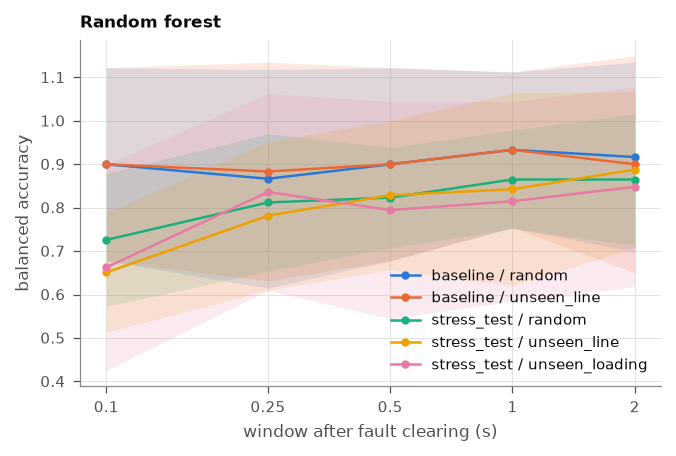

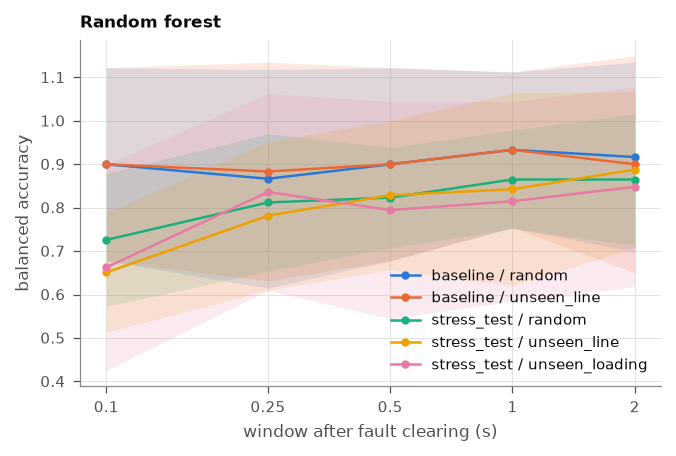

In [9]:
import matplotlib.pyplot as plt
from tranpy_core.plotting import plot_metric_curves, publication_style, save_figure

rf = results[results["model"] == "random_forest"].copy()
rf["setting"] = rf["protocol"] + " / " + rf["split"]
with publication_style():
    fig, ax = plt.subplots(figsize=(5.0, 3.0))
    plot_metric_curves(rf, x="window_s", y="balanced_accuracy_mean", group="setting",
                       band="balanced_accuracy_ci95", ax=ax, logx=True,
                       xlabel="window after fault clearing (s)", ylabel="balanced accuracy",
                       title="Random forest")
    save_figure(fig, RESULTS / "random_forest_balanced_accuracy.pdf")
fig

## Provenance

In [10]:
import andes, sklearn
config = dict(system=SYSTEM, engine_options=ENGINE_OPTIONS, n_scenarios=N_SCENARIOS, seed=SEED, protocols=PROTOCOLS, models=MODELS,
              windows_s=list(WINDOWS_S), n_splits=N_SPLITS, n_repeats=N_REPEATS,
              andes=andes.__version__, sklearn=sklearn.__version__,
              stress_test=repr(stress), baseline=repr(baseline))
(RESULTS / "config.json").write_text(json.dumps(config, indent=2))
sorted(p.name for p in RESULTS.iterdir())

['balanced_accuracy.csv',
 'config.json',
 'dataset_summary.csv',
 'events_baseline.npz',
 'events_stress_test.npz',
 'random_forest_balanced_accuracy.pdf',
 'results.csv',
 'roc_auc.csv']